In [1]:
import gc
import math
import random
import time

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    ConcatDataset,
    DataLoader,
    random_split
)

from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
BATCH_SIZE = 128

LATENT_DIM = 64
GAN_LATENT_DIM = 100
DCGAN_LATENT_DIM = 100
TIMESTEPS = 1000

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


In [2]:
# CP load

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
SOURCE_OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR = SOURCE_OUTPUT_DIR / "comparison"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

required = [
    "vanilla_ae.pt",
    "sparse_ae.pt",
    "vae.pt",
    "vanilla_gan_generator.pt",
    "vanilla_gan_discriminator.pt",
    "dcgan_generator.pt",
    "dcgan_discriminator.pt",
    "ddpm.pt",
    "mlp_classifier.pt",
    "mlp_frozen_decoder.pt",
    "mlp_latent_prior.pt"
]

audit = pd.DataFrame([
    {
        "checkpoint": name,
        "exists": (CHECKPOINT_DIR / name).is_file(),
        "bytes": (
            (CHECKPOINT_DIR / name).stat().st_size
            if (CHECKPOINT_DIR / name).is_file()
            else 0
        )
    }
    for name in required
])

display(audit)

missing = audit.loc[
    ~audit["exists"],
    "checkpoint"
].tolist()

assert not missing, (
    f"Missing checkpoints: {missing}. "
    "Check Google Drive before continuing."
)

print("All 11 checkpoints present:", CHECKPOINT_DIR)


Mounted at /content/drive


,checkpoint,exists,bytes
0,vanilla_ae.pt,True,1745655
1,sparse_ae.pt,True,1745641
2,vae.pt,True,1811205
3,vanilla_gan_generator.pt,True,2241597
4,vanilla_gan_discriminator.pt,True,2137261
5,dcgan_generator.pt,True,3045465
6,dcgan_discriminator.pt,True,559485
7,ddpm.pt,True,3777581
8,mlp_classifier.pt,True,875177
9,mlp_frozen_decoder.pt,True,875019


All 11 checkpoints present: /content/drive/MyDrive/Model_Comparison/checkpoints


In [3]:
# Data

transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    "./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    "./data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print(
    "Train/Val/Test:",
    len(train_dataset),
    len(val_dataset),
    len(test_dataset)
)


100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 207kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.2MB/s]

Train/Val/Test: 56000 7000 7000


In [4]:
# 1. Vanilla Autoencoder

class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)

        return reconstructed.view(-1, 1, 28, 28)


# 2. Sparse Autoencoder

class SparseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)

        return reconstructed.view(-1, 1, 28, 28), z


# 3. Variational Autoencoder

class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        hidden = self.encoder(x)

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        z = self.reparameterize(mu, logvar)

        reconstructed = self.decoder(z)
        reconstructed = reconstructed.view(-1, 1, 28, 28)

        return reconstructed, mu, logvar


# 4. Vanilla GAN

class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 512),
            nn.ReLU(),

            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        generated = self.model(z)
        return generated.view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.model(x)


# 5. DCGAN

class DCGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.latent_dim = latent_dim

        self.model = nn.Sequential(
            nn.ConvTranspose2d(
                latent_dim, 128,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, z):
        z = z.view(-1, self.latent_dim, 1, 1)
        return self.model(z)


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                128, 1,
                kernel_size=7,
                stride=1,
                padding=0
            )
        )

    def forward(self, x):
        output = self.model(x)
        return output.view(-1, 1)


# 6. DDPM Timestep Embedding

class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2

        emb_factor = math.log(10000) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(
                half_dim,
                device=t.device
            ) * -emb_factor
        )

        emb = t.float()[:, None] * emb[None, :]

        return torch.cat(
            [emb.sin(), emb.cos()],
            dim=1
        )


# DDPM Residual Block

class ResBlock(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        time_emb_dim
    ):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(
                time_emb_dim,
                out_channels
            )
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels)
        )

        self.residual_conv = (
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, t_emb):
        h = self.block1(x)

        time_emb = self.time_mlp(t_emb)
        h = h + time_emb[:, :, None, None]

        h = self.block2(h)

        return F.silu(
            h + self.residual_conv(x)
        )


# DDPM U-Net

class DDPMUNet(nn.Module):
    def __init__(self, time_emb_dim=128):
        super().__init__()

        self.time_mlp = nn.Sequential(
            SinusoidalPosEmb(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )

        self.init_conv = nn.Conv2d(
            1, 32, kernel_size=3, padding=1
        )

        # Encoder

        self.down_block1 = ResBlock(
            32, 32, time_emb_dim
        )

        self.downsample1 = nn.Conv2d(
            32, 64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.down_block2 = ResBlock(
            64, 64, time_emb_dim
        )

        self.downsample2 = nn.Conv2d(
            64, 128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.mid_block = ResBlock(
            128, 128, time_emb_dim
        )

        # Decoder

        self.upsample1 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block1 = ResBlock(
            128, 64, time_emb_dim
        )

        self.upsample2 = nn.ConvTranspose2d(
            64, 32,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block2 = ResBlock(
            64, 32, time_emb_dim
        )

        self.output_conv = nn.Conv2d(
            32, 1, kernel_size=1
        )

    def forward(self, x, t):
        t_emb = self.time_mlp(t)

        x = self.init_conv(x)

        # Encode

        h1 = self.down_block1(x, t_emb)
        x = self.downsample1(h1)

        h2 = self.down_block2(x, t_emb)
        x = self.downsample2(h2)

        x = self.mid_block(x, t_emb)

        # Decode + Skip Connections

        x = self.upsample1(x)
        x = torch.cat([x, h2], dim=1)
        x = self.up_block1(x, t_emb)

        x = self.upsample2(x)
        x = torch.cat([x, h1], dim=1)
        x = self.up_block2(x, t_emb)

        return self.output_conv(x)


# 7. MLP Classifier

class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def extract_features(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        z = self.relu(self.fc2(x))

        return z

    def forward(self, x):
        z = self.extract_features(x)
        return self.fc3(z)


# 8. Frozen MLP Decoder

class FrozenLatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        reconstructed = self.decoder(z)

        return reconstructed.view(-1, 1, 28, 28)


print("All model architecture classes are ready!")


All model architecture classes are ready!


In [5]:
# Load CP

vanilla_ae = VanillaAE().to(DEVICE)
sparse_ae = SparseAE().to(DEVICE)
vae = VAE(latent_dim=LATENT_DIM).to(DEVICE)

generator = Generator(
    GAN_LATENT_DIM
).to(DEVICE)

discriminator = Discriminator().to(DEVICE)

dc_generator = DCGenerator(
    DCGAN_LATENT_DIM
).to(DEVICE)

dc_discriminator = DCDiscriminator().to(DEVICE)

ddpm_model = DDPMUNet(
    time_emb_dim=128
).to(DEVICE)

mlp_classifier = MLPClassifier().to(DEVICE)
mlp_decoder = FrozenLatentDecoder().to(DEVICE)


models = {
    "Vanilla AE": vanilla_ae,
    "Sparse AE": sparse_ae,
    "VAE": vae,
    "Vanilla GAN Generator": generator,
    "Vanilla GAN Discriminator": discriminator,
    "DCGAN Generator": dc_generator,
    "DCGAN Discriminator": dc_discriminator,
    "DDPM": ddpm_model,
    "MLP Classifier": mlp_classifier,
    "Frozen MLP Decoder": mlp_decoder
}

checkpoint_files = {
    "Vanilla AE": "vanilla_ae.pt",
    "Sparse AE": "sparse_ae.pt",
    "VAE": "vae.pt",
    "Vanilla GAN Generator": "vanilla_gan_generator.pt",
    "Vanilla GAN Discriminator": "vanilla_gan_discriminator.pt",
    "DCGAN Generator": "dcgan_generator.pt",
    "DCGAN Discriminator": "dcgan_discriminator.pt",
    "DDPM": "ddpm.pt",
    "MLP Classifier": "mlp_classifier.pt",
    "Frozen MLP Decoder": "mlp_frozen_decoder.pt"
}


for name, model in models.items():

    checkpoint_path = (
        CHECKPOINT_DIR / checkpoint_files[name]
    )

    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(
        state_dict,
        strict=True
    )

    model.eval()

    print(f"Loaded: {name}")


prior = torch.load(
    CHECKPOINT_DIR / "mlp_latent_prior.pt",
    map_location="cpu",
    weights_only=True
)

print("\nMLP latent prior keys:", list(prior.keys()))

print("\nAll checkpoints loaded successfully!")


Loaded: Vanilla AE
Loaded: Sparse AE
Loaded: VAE
Loaded: Vanilla GAN Generator
Loaded: Vanilla GAN Discriminator
Loaded: DCGAN Generator
Loaded: DCGAN Discriminator
Loaded: DDPM
Loaded: MLP Classifier
Loaded: Frozen MLP Decoder

MLP latent prior keys: ['mean', 'std', 'source']

All checkpoints loaded successfully!


Reconstruction Metrics:


,Model,Test MSE,Test PSNR (dB),Test SSIM
0,Vanilla AE,0.007078,22.564558,0.815838
1,Sparse AE,0.009742,21.056206,0.759659
2,VAE,0.017936,18.128990,0.631546


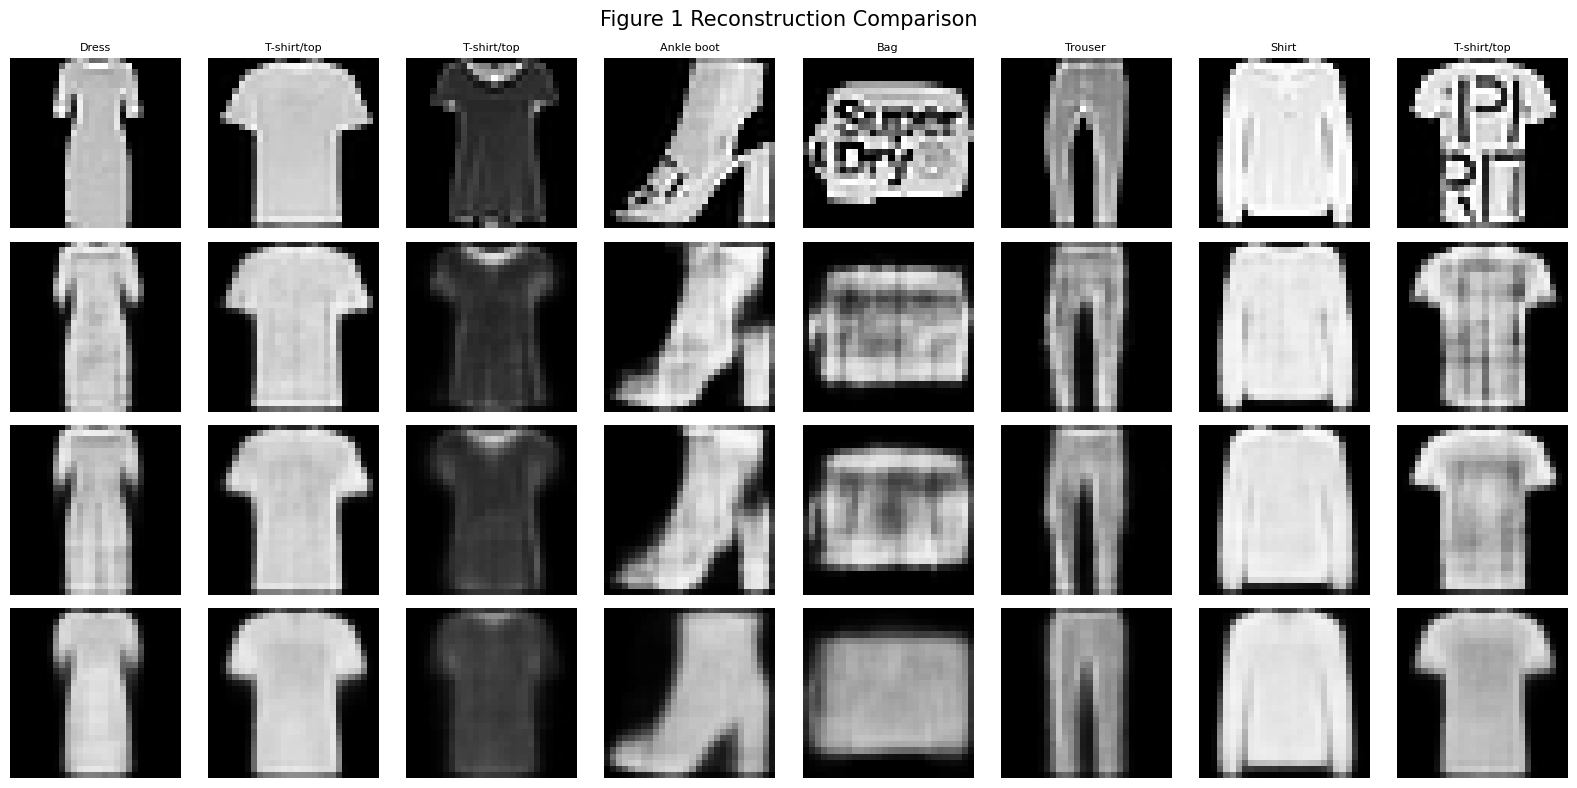

Figure 1 saved successfully!


In [ ]:
# Reconstruct dan Figure 1

metric_files = {
    "Vanilla AE": (
        SOURCE_OUTPUT_DIR / "vanilla_ae" / "test_metrics.csv"
    ),
    "Sparse AE": (
        SOURCE_OUTPUT_DIR / "sparse_ae" / "test_metrics.csv"
    ),
    "VAE": (
        SOURCE_OUTPUT_DIR / "vae" / "test_metrics.csv"
    )
}

rows = []

for name, path in metric_files.items():

    assert path.is_file(), (
        f"Missing saved metrics: {path}"
    )

    rec = pd.read_csv(path).iloc[0]

    rows.append({
        "Model": name,
        "Test MSE": float(rec["test_mse"]),
        "Test PSNR (dB)": float(rec["test_psnr"]),
        "Test SSIM": float(rec["test_ssim"])
    })

reconstruction_metrics = pd.DataFrame(rows)

reconstruction_metrics.to_csv(
    OUTPUT_DIR / "reconstruction_metrics.csv",
    index=False
)

print("Reconstruction Metrics:")
display(reconstruction_metrics)


# Figure 1 -> Reconstruction Comparison

fig1_images, fig1_labels = next(iter(test_loader))

fig1_images = fig1_images[:8].to(DEVICE)

with torch.inference_mode():

    ae_recon = vanilla_ae(fig1_images)

    sparse_recon, _ = sparse_ae(fig1_images)

    mu = vae.fc_mu(
        vae.encoder(fig1_images)
    )

    vae_recon = vae.decoder(mu).view(
        -1, 1, 28, 28
    )


rows_display = [
    ("Original", fig1_images),
    ("Vanilla AE", ae_recon),
    ("Sparse AE", sparse_recon),
    ("VAE", vae_recon)
]

fig, axs = plt.subplots(
    4, 8,
    figsize=(16, 8)
)

for r, (name, images) in enumerate(rows_display):

    for c in range(8):

        image = (
            images[c, 0]
            .detach()
            .cpu()
            .numpy()
        )

        axs[r, c].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axs[r, c].axis("off")

        if r == 0:
            axs[r, c].set_title(
                class_names[int(fig1_labels[c])],
                fontsize=8
            )

    axs[r, 0].set_ylabel(
        name,
        rotation=90,
        fontsize=10
    )

fig.suptitle(
    "Figure 1 Reconstruction Comparison",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_1_reconstruction.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 saved successfully!")


In [ ]:
# DDPM Schedule and Sampling

betas = torch.linspace(
    0.0001,
    0.02,
    TIMESTEPS,
    device=DEVICE
)

alphas = 1.0 - betas

alphas_cumprod = torch.cumprod(
    alphas,
    dim=0
)

alphas_cumprod_prev = torch.cat([
    torch.ones(1, device=DEVICE),
    alphas_cumprod[:-1]
])

posterior_variance = (
    betas
    * (1.0 - alphas_cumprod_prev)
    / (1.0 - alphas_cumprod)
).clamp(min=1e-20)


def extract(schedule, t, shape):

    values = schedule.gather(0, t)

    return values.reshape(
        t.size(0),
        *([1] * (len(shape) - 1))
    )


# DDPM Reverse Diffusion

@torch.inference_mode()
def p_sample(model, x, t):

    beta_t = extract(
        betas,
        t,
        x.shape
    )

    sqrt_one_minus_alpha_bar = extract(
        torch.sqrt(1.0 - alphas_cumprod),
        t,
        x.shape
    )

    sqrt_recip_alpha = extract(
        torch.sqrt(1.0 / alphas),
        t,
        x.shape
    )

    predicted_noise = model(x, t)

    model_mean = sqrt_recip_alpha * (
        x
        - beta_t
        / sqrt_one_minus_alpha_bar
        * predicted_noise
    )

    noise = torch.randn_like(x)

    nonzero_mask = (
        (t != 0)
        .float()
        .view(-1, 1, 1, 1)
    )

    variance_t = extract(
        posterior_variance,
        t,
        x.shape
    )

    return (
        model_mean
        + nonzero_mask
        * torch.sqrt(variance_t)
        * noise
    )


# DDPM Full Sampling

@torch.inference_mode()
def ddpm_sample(
    model,
    num_samples=16,
    with_trajectory=False
):

    model.eval()

    x = torch.randn(
        num_samples,
        1,
        28,
        28,
        device=DEVICE
    )

    trajectory = (
        {999: x[0].cpu().clone()}
        if with_trajectory
        else {}
    )

    for step in reversed(range(TIMESTEPS)):

        t = torch.full(
            (num_samples,),
            step,
            device=DEVICE,
            dtype=torch.long
        )

        x = p_sample(
            model,
            x,
            t
        )

        if (
            with_trajectory
            and step in [800, 600, 400, 200, 100, 0]
        ):
            trajectory[step] = (
                x[0].cpu().clone()
            )

    return x, trajectory


# VAE Sampling

@torch.inference_mode()
def sample_vae(n):

    z = torch.randn(
        n,
        LATENT_DIM,
        device=DEVICE
    )

    return vae.decoder(z).view(
        n, 1, 28, 28
    )


# Vanilla GAN Sampling

@torch.inference_mode()
def sample_gan(n):

    z = torch.randn(
        n,
        GAN_LATENT_DIM,
        device=DEVICE
    )

    return generator(z)


# DCGAN Sampling

@torch.inference_mode()
def sample_dcgan(n):

    z = torch.randn(
        n,
        DCGAN_LATENT_DIM,
        device=DEVICE
    )

    return dc_generator(z)


# DDPM Sampling

@torch.inference_mode()
def sample_ddpm(n):

    generated, _ = ddpm_sample(
        ddpm_model,
        num_samples=n
    )

    return generated


print("Samplers ready")


Samplers ready


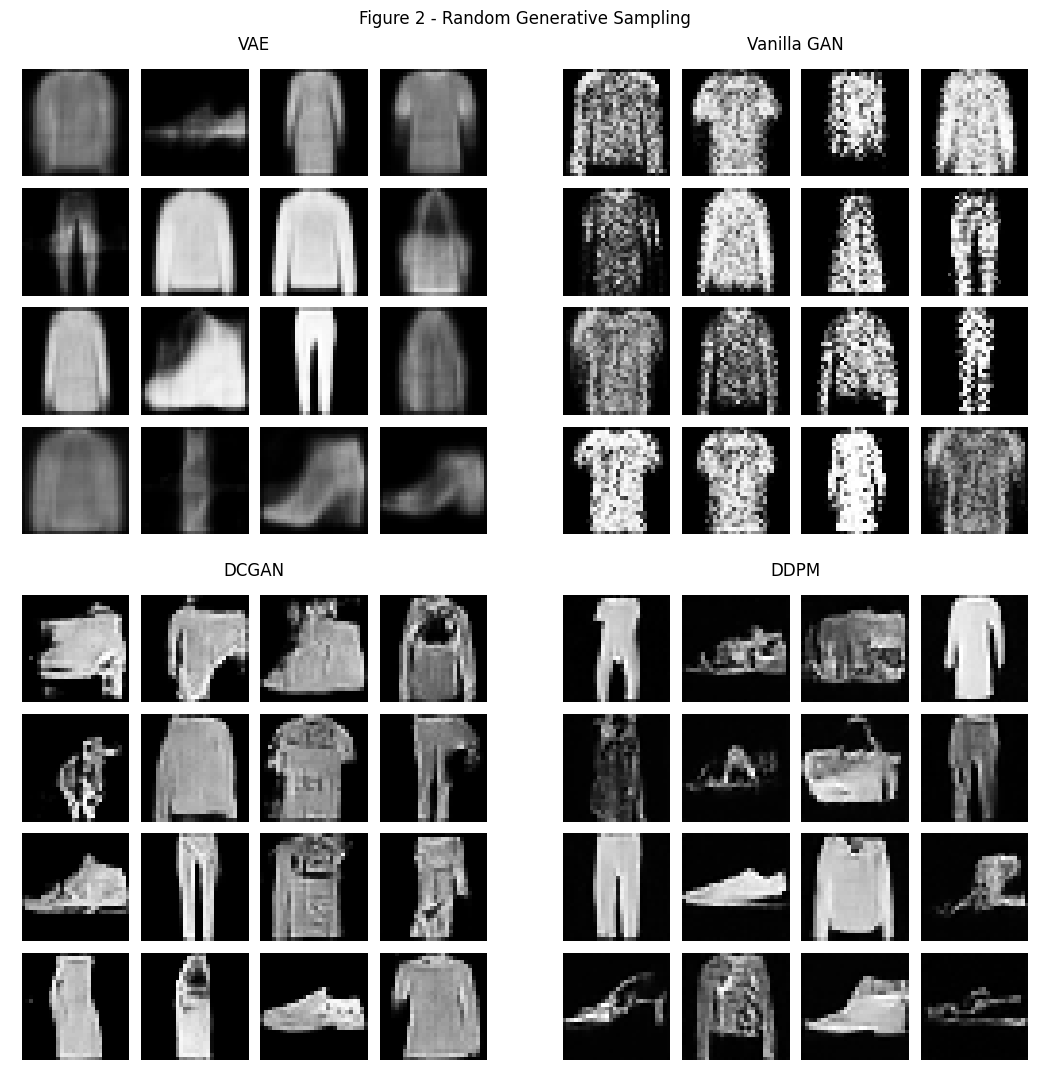

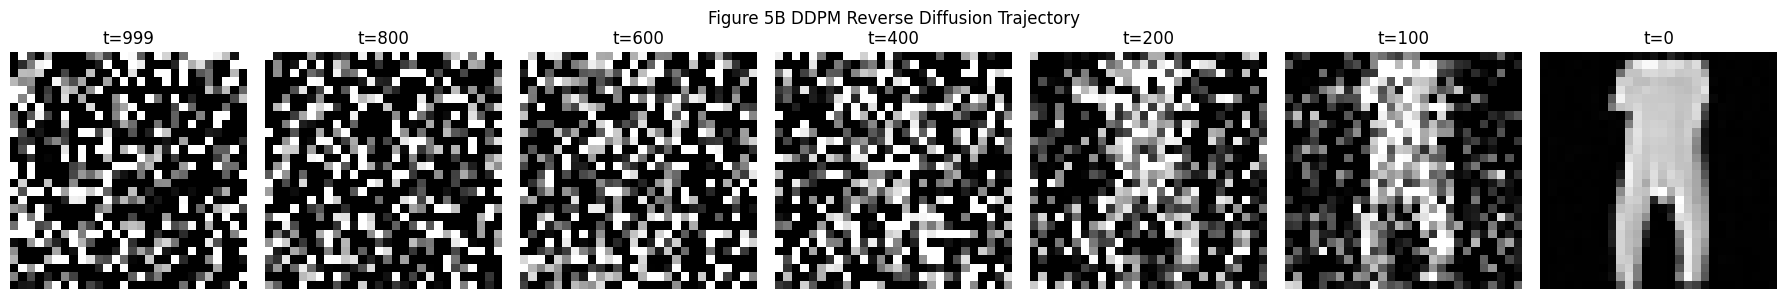

Figure 2 saved successfully!
DDPM trajectory saved successfully!


In [ ]:
# DDPM Trajectory dan Figure 2

torch.manual_seed(SEED + 2026)

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED + 2026)


with torch.inference_mode():

    ddpm_generated, ddpm_trajectory = ddpm_sample(
        ddpm_model,
        num_samples=16,
        with_trajectory=True
    )

    samples = {
        "VAE": sample_vae(16),
        "Vanilla GAN": sample_gan(16),
        "DCGAN": sample_dcgan(16),
        "DDPM": ddpm_generated
    }


# Figure 2

fig, axs = plt.subplots(
    2, 2,
    figsize=(11, 11)
)

for ax, (name, images) in zip(
    axs.flat,
    samples.items()
):

    grid = make_grid(
        images.cpu().clamp(0, 1),
        nrow=4,
        padding=3,
        pad_value=1
    )

    ax.imshow(
        grid[0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(name)
    ax.axis("off")

fig.suptitle(
    "Figure 2 - Random Generative Sampling"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_2_random_sampling.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# Figure 5B

steps = sorted(
    ddpm_trajectory,
    reverse=True
)

fig, axs = plt.subplots(
    1,
    len(steps),
    figsize=(18, 3)
)

for ax, t in zip(axs, steps):

    image = (
        ddpm_trajectory[t][0]
        .clamp(0, 1)
        .numpy()
    )

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"t={t}")
    ax.axis("off")

fig.suptitle(
    "Figure 5B DDPM Reverse Diffusion Trajectory"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_5_ddpm_trajectory.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 saved successfully!")
print("DDPM trajectory saved successfully!")


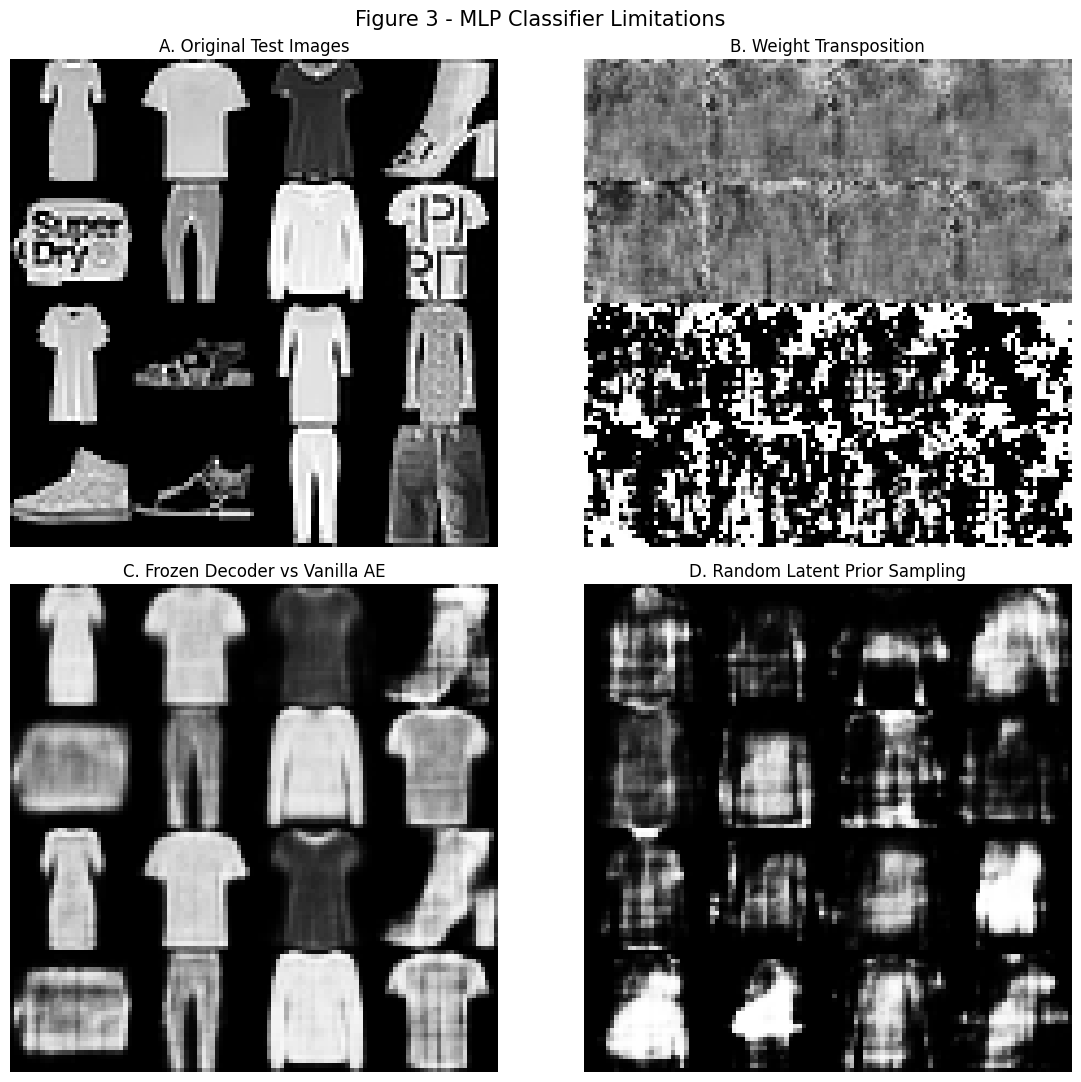

Figure 3 saved successfully!


In [6]:
# MLP Limitations


mlp_classifier.eval()
mlp_decoder.eval()
vanilla_ae.eval()


fig3_images, fig3_labels = next(
    iter(test_loader)
)

fig3_images = fig3_images[:16].to(DEVICE)
fig3_labels = fig3_labels[:16].to(DEVICE)


with torch.inference_mode():

    W1 = mlp_classifier.fc1.weight.detach()
    W2 = mlp_classifier.fc2.weight.detach()
    W3 = mlp_classifier.fc3.weight.detach()


    class_vectors = F.one_hot(
        fig3_labels[:8],
        num_classes=10
    ).float()

    class_projection = torch.sigmoid(
        F.relu(
            F.relu(class_vectors @ W3) @ W2
        ) @ W1
    ).view(-1, 1, 28, 28)


    z_mlp = mlp_classifier.extract_features(
        fig3_images[:8]
    )

    latent_projection = torch.sigmoid(
        F.relu(z_mlp @ W2) @ W1
    ).view(-1, 1, 28, 28)


    frozen_reconstruction = mlp_decoder(
        z_mlp
    )

    ae_reconstruction = vanilla_ae(
        fig3_images[:8]
    )

    latent_mean = prior["mean"].to(DEVICE)
    latent_std = prior["std"].to(DEVICE)

    random_generator = torch.Generator(
        device=DEVICE
    )

    random_generator.manual_seed(SEED + 200)

    random_latents = (
        latent_mean.unsqueeze(0)
        + torch.randn(
            16,
            LATENT_DIM,
            generator=random_generator,
            device=DEVICE
        ) * latent_std.unsqueeze(0)
    )

    random_generated = mlp_decoder(
        random_latents
    )


# Figure 3

fig3_panels = {
    "A. Original Test Images": fig3_images,

    "B. Weight Transposition": torch.cat([
        class_projection,
        latent_projection
    ], dim=0),

    "C. Frozen Decoder vs Vanilla AE": torch.cat([
        frozen_reconstruction,
        ae_reconstruction
    ], dim=0),

    "D. Random Latent Prior Sampling":
        random_generated
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 11)
)

for ax, (title, images) in zip(
    axes.flat,
    fig3_panels.items()
):

    images_np = (
        images.detach().cpu().numpy()
    )

    image_grid = np.concatenate([
        np.concatenate(
            [
                images_np[row * 4 + col, 0]
                for col in range(4)
            ],
            axis=1
        )
        for row in range(4)
    ], axis=0)

    ax.imshow(
        image_grid,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.axis("off")


fig.suptitle(
    "Figure 3 - MLP Classifier Limitations",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_3_mlp_limitations.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved successfully!")


In [7]:
print("Prior source:", prior["source"])
print("Mean shape:", prior["mean"].shape)
print("Std shape:", prior["std"].shape)

assert prior["source"] == "test_set"
assert prior["mean"].shape == (64,)
assert prior["std"].shape == (64,)

print("MLP prior verification passed!")

Prior source: test_set
Mean shape: torch.Size([64])
Std shape: torch.Size([64])
MLP prior verification passed!


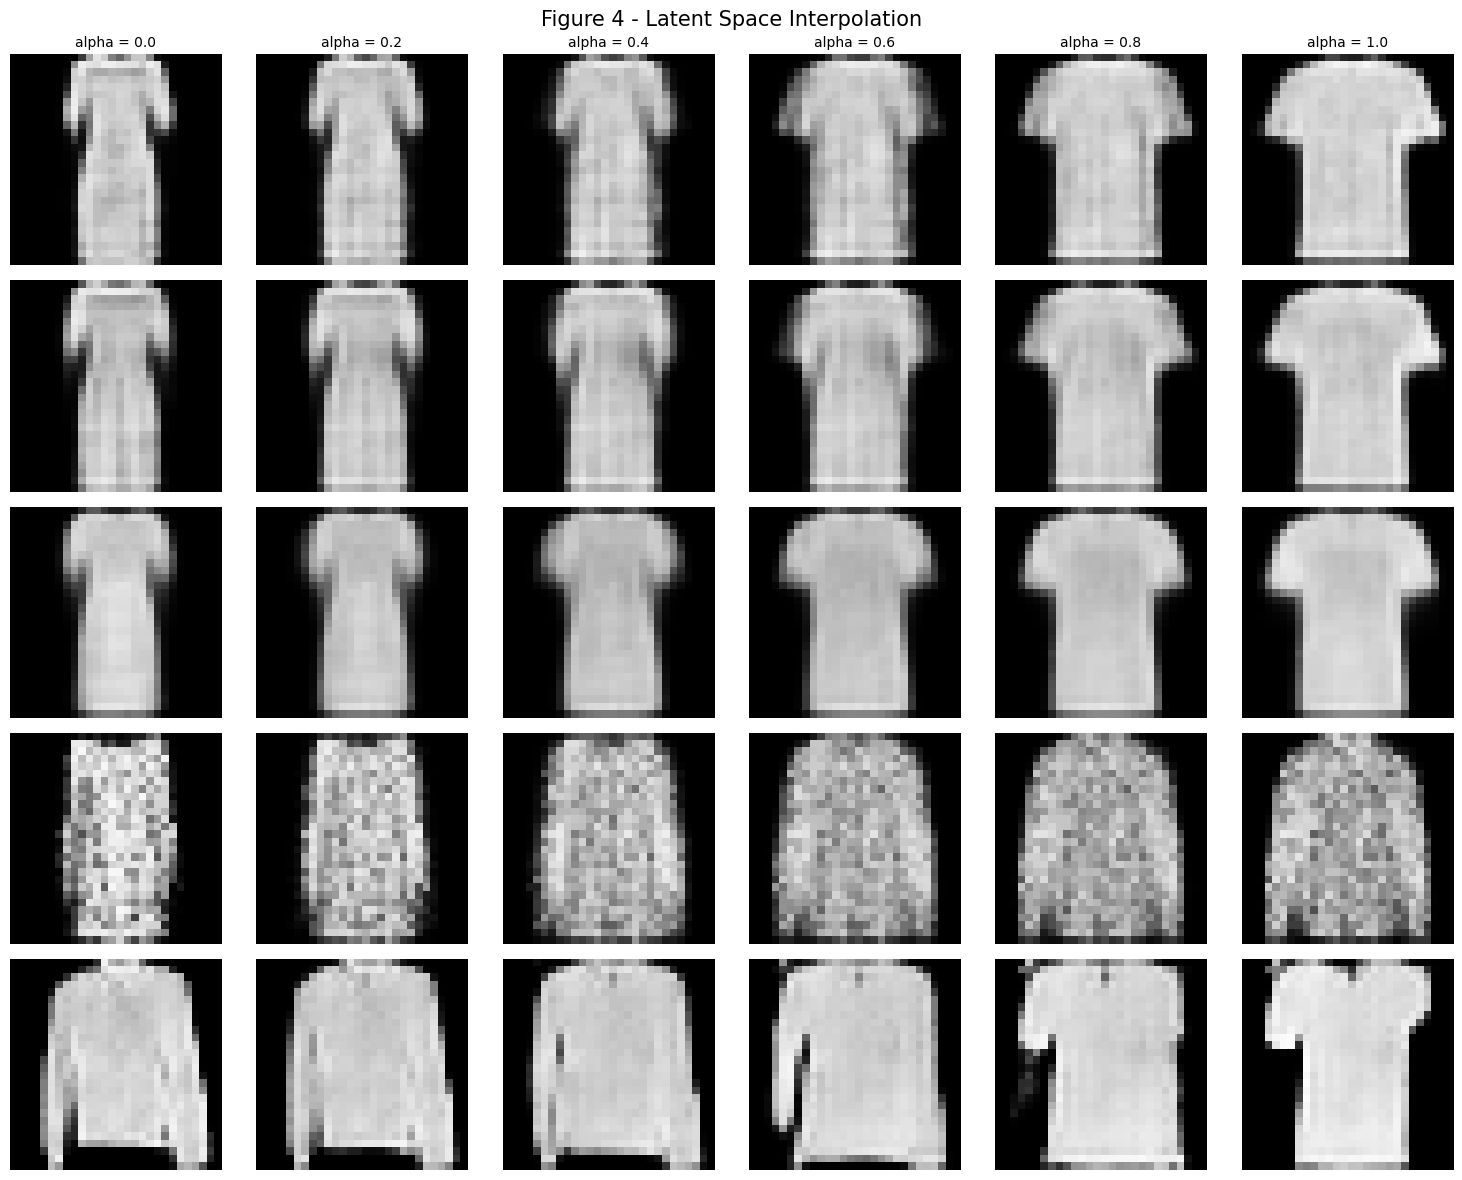

Figure 4 saved successfully!
Interpolation classes: Dress -> T-shirt/top


In [ ]:
# Figure 4

vanilla_ae.eval()
sparse_ae.eval()
vae.eval()
generator.eval()
dc_generator.eval()

interp_alphas = torch.linspace(
    0.0, 1.0, steps=6, device=DEVICE
)

images, labels = next(iter(test_loader))

idx_a = 0
idx_b = next(
    i for i in range(1, len(labels))
    if labels[i] != labels[idx_a]
)

x_a = images[idx_a:idx_a+1].to(DEVICE)
x_b = images[idx_b:idx_b+1].to(DEVICE)

latent_rng = torch.Generator(device=DEVICE)
latent_rng.manual_seed(SEED + 400)

gan_z_a = torch.randn(
    1, GAN_LATENT_DIM,
    generator=latent_rng,
    device=DEVICE
)

gan_z_b = torch.randn(
    1, GAN_LATENT_DIM,
    generator=latent_rng,
    device=DEVICE
)

dc_z_a = torch.randn(
    1, DCGAN_LATENT_DIM,
    generator=latent_rng,
    device=DEVICE
)

dc_z_b = torch.randn(
    1, DCGAN_LATENT_DIM,
    generator=latent_rng,
    device=DEVICE
)


def interpolate_latents(z_a, z_b, alpha_values):
    return torch.cat([
        (1 - alpha) * z_a + alpha * z_b
        for alpha in alpha_values
    ], dim=0)


with torch.inference_mode():

    ae_z_a = vanilla_ae.encoder(x_a)
    ae_z_b = vanilla_ae.encoder(x_b)

    ae_interpolated = vanilla_ae.decoder(
        interpolate_latents(
            ae_z_a, ae_z_b, interp_alphas
        )
    ).view(-1, 1, 28, 28)

    sparse_z_a = sparse_ae.encoder(x_a)
    sparse_z_b = sparse_ae.encoder(x_b)

    sparse_interpolated = sparse_ae.decoder(
        interpolate_latents(
            sparse_z_a, sparse_z_b, interp_alphas
        )
    ).view(-1, 1, 28, 28)

    vae_z_a = vae.fc_mu(
        vae.encoder(x_a)
    )

    vae_z_b = vae.fc_mu(
        vae.encoder(x_b)
    )

    vae_interpolated = vae.decoder(
        interpolate_latents(
            vae_z_a, vae_z_b, interp_alphas
        )
    ).view(-1, 1, 28, 28)

    gan_interpolated = generator(
        interpolate_latents(
            gan_z_a, gan_z_b, interp_alphas
        )
    )

    dcgan_interpolated = dc_generator(
        interpolate_latents(
            dc_z_a, dc_z_b, interp_alphas
        )
    )


interpolations = {
    "Vanilla AE": ae_interpolated,
    "Sparse AE": sparse_interpolated,
    "VAE": vae_interpolated,
    "Vanilla GAN": gan_interpolated,
    "DCGAN": dcgan_interpolated
}

fig, axes = plt.subplots(
    5, 6,
    figsize=(15, 12)
)

for row, (model_name, generated) in enumerate(
    interpolations.items()
):

    for col, alpha in enumerate(interp_alphas):

        image = (
            generated[col, 0]
            .detach()
            .cpu()
            .clamp(0, 1)
            .numpy()
        )

        axes[row, col].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                f"alpha = {alpha.item():.1f}",
                fontsize=10
            )

    axes[row, 0].set_ylabel(
        model_name,
        fontsize=11,
        rotation=90,
        labelpad=15
    )


fig.suptitle(
    "Figure 4 - Latent Space Interpolation",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_4_interpolation.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Figure 4 saved successfully!")
print(
    "Interpolation classes:",
    class_names[int(labels[idx_a])],
    "->",
    class_names[int(labels[idx_b])]
)


Loaded: Vanilla AE | Epochs: 20
Loaded: Sparse AE | Epochs: 20
Loaded: VAE | Epochs: 20
Loaded: Vanilla GAN | Epochs: 20
Loaded: DCGAN | Epochs: 20
Loaded: DDPM | Epochs: 20


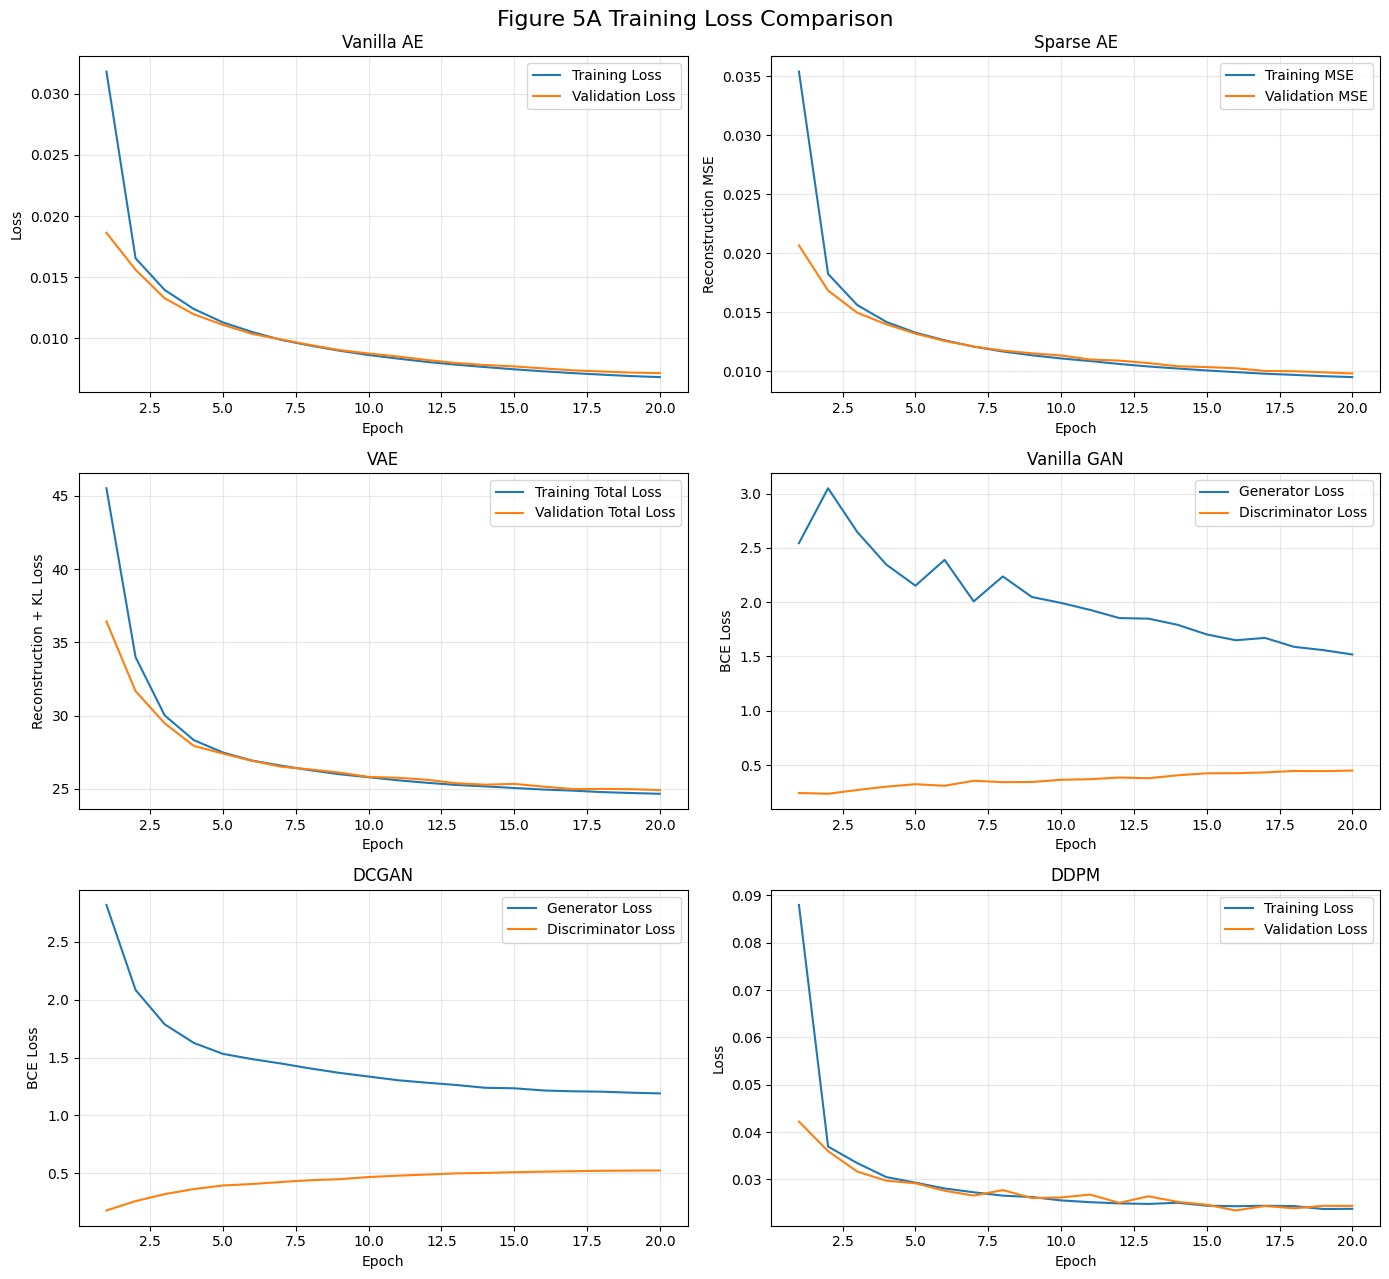

Figure 5A saved successfully!


In [ ]:

# Training Loss Comparison

history_files = {
    "Vanilla AE": SOURCE_OUTPUT_DIR / "vanilla_ae" / "loss_history.csv",
    "Sparse AE": SOURCE_OUTPUT_DIR / "sparse_ae" / "loss_history.csv",
    "VAE": SOURCE_OUTPUT_DIR / "vae" / "loss_history.csv",
    "Vanilla GAN": SOURCE_OUTPUT_DIR / "vanilla_gan" / "loss_history.csv",
    "DCGAN": SOURCE_OUTPUT_DIR / "dcgan" / "loss_history.csv",
    "DDPM": SOURCE_OUTPUT_DIR / "ddpm" / "loss_history.csv"
}

histories = {}

for name, path in history_files.items():

    assert path.is_file(), f"Missing history: {path}"

    histories[name] = pd.read_csv(path)

    print(
        f"Loaded: {name} | "
        f"Epochs: {len(histories[name])}"
    )

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 13)
)

for ax, (name, df) in zip(
    axes.flat,
    histories.items()
):

    epochs = df["epoch"]

    if name in ["Vanilla GAN", "DCGAN"]:

        ax.plot(
            epochs,
            df["generator_loss"],
            label="Generator Loss"
        )

        ax.plot(
            epochs,
            df["discriminator_loss"],
            label="Discriminator Loss"
        )

        ax.set_ylabel("BCE Loss")

    elif name == "Sparse AE":

        ax.plot(
            epochs,
            df["train_mse"],
            label="Training MSE"
        )

        ax.plot(
            epochs,
            df["val_mse"],
            label="Validation MSE"
        )

        ax.set_ylabel("Reconstruction MSE")

    elif name == "VAE":

        ax.plot(
            epochs,
            df["train_loss"],
            label="Training Total Loss"
        )

        ax.plot(
            epochs,
            df["val_loss"],
            label="Validation Total Loss"
        )

        ax.set_ylabel("Reconstruction + KL Loss")

    else:

        ax.plot(
            epochs,
            df["train_loss"],
            label="Training Loss"
        )

        ax.plot(
            epochs,
            df["val_loss"],
            label="Validation Loss"
        )

        ax.set_ylabel("Loss")

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Figure 5A Training Loss Comparison",
    fontsize=16
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_5_training_losses.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Figure 5A saved successfully!")


In [ ]:
# Inference Latency Benchmark

BENCHMARK_BATCH_SIZE = 64
DDPM_CHUNK_SIZE = 16
WARMUP = 1
REPEATS = 3



training_times = {}

for name, df in histories.items():

    assert "epoch_time_s" in df.columns, (
        f"Missing epoch_time_s for {name}"
    )

    training_times[name] = float(
        df["epoch_time_s"].mean()
    )

print("Training times loaded successfully!")

benchmark_images = torch.rand(
    BENCHMARK_BATCH_SIZE,
    1, 28, 28,
    device=DEVICE
)

vae_noise = torch.randn(
    BENCHMARK_BATCH_SIZE,
    LATENT_DIM,
    device=DEVICE
)

gan_noise = torch.randn(
    BENCHMARK_BATCH_SIZE,
    GAN_LATENT_DIM,
    device=DEVICE
)

dcgan_noise = torch.randn(
    BENCHMARK_BATCH_SIZE,
    DCGAN_LATENT_DIM,
    device=DEVICE
)

for model in [
    vanilla_ae,
    sparse_ae,
    vae,
    generator,
    dc_generator,
    ddpm_model
]:
    model.eval()

@torch.inference_mode()
def generate_ddpm_batch64():

    generated_chunks = []

    for start in range(
        0,
        BENCHMARK_BATCH_SIZE,
        DDPM_CHUNK_SIZE
    ):

        current_batch = min(
            DDPM_CHUNK_SIZE,
            BENCHMARK_BATCH_SIZE - start
        )

        generated, _ = ddpm_sample(
            ddpm_model,
            num_samples=current_batch,
            with_trajectory=False
        )

        generated_chunks.append(generated)

    return torch.cat(
        generated_chunks,
        dim=0
    )

@torch.inference_mode()
def benchmark_vae():

    return vae.decoder(
        vae_noise
    ).view(-1, 1, 28, 28)


benchmarks = {
    "Vanilla AE": lambda: vanilla_ae(
        benchmark_images
    ),

    "Sparse AE": lambda: sparse_ae(
        benchmark_images
    )[0],

    "VAE": benchmark_vae,

    "Vanilla GAN": lambda: generator(
        gan_noise
    ),

    "DCGAN": lambda: dc_generator(
        dcgan_noise
    ),

    "DDPM": generate_ddpm_batch64
}

def synchronize_device():

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


benchmark_rows = []
raw_measurements = []

for name, function in benchmarks.items():

    print(f"\nBenchmarking: {name}", flush=True)


    for _ in range(WARMUP):

        with torch.inference_mode():
            warmup_output = function()

        synchronize_device()

    del warmup_output

    latencies = []

    for repeat in range(REPEATS):

        synchronize_device()

        start_time = time.perf_counter()

        with torch.inference_mode():
            output = function()

        synchronize_device()

        elapsed_ms = (
            time.perf_counter() - start_time
        ) * 1000

        assert output.shape == (
            BENCHMARK_BATCH_SIZE, 1, 28, 28
        ), f"Unexpected output shape for {name}"

        assert torch.isfinite(output).all().item(), (
            f"Non-finite output from {name}"
        )

        latencies.append(elapsed_ms)

        raw_measurements.append({
            "Model": name,
            "repeat": repeat + 1,
            "latency_ms": elapsed_ms
        })

        print(
            f"  Repeat {repeat+1}/{REPEATS}: "
            f"{elapsed_ms:.2f} ms",
            flush=True
        )

        del output

    median_latency = float(
        np.median(latencies)
    )

    mean_latency = float(
        np.mean(latencies)
    )

    benchmark_rows.append({
        "Model": name,
        "Training Time (s/epoch)": training_times[name],
        "Inference Latency (ms/batch64)": median_latency,
        "Mean Latency (ms/batch64)": mean_latency
    })

    print(
        f"  Median Latency: {median_latency:.2f} ms",
        flush=True
    )

    pd.DataFrame(
        benchmark_rows
    ).to_csv(
        OUTPUT_DIR / "benchmark_results_final.csv",
        index=False
    )

    pd.DataFrame(
        raw_measurements
    ).to_csv(
        OUTPUT_DIR / "benchmark_raw_measurements.csv",
        index=False
    )


benchmark_results = pd.DataFrame(
    benchmark_rows
)

print("\nInference Latency Benchmark Complete!")

display(benchmark_results)

print(
    "Saved results to:",
    OUTPUT_DIR
)


Training times loaded successfully!

Benchmarking: Vanilla AE
  Repeat 1/3: 0.45 ms
  Repeat 2/3: 0.43 ms
  Repeat 3/3: 0.93 ms
  Median Latency: 0.45 ms

Benchmarking: Sparse AE
  Repeat 1/3: 1.20 ms
  Repeat 2/3: 0.64 ms
  Repeat 3/3: 0.81 ms
  Median Latency: 0.81 ms

Benchmarking: VAE
  Repeat 1/3: 0.38 ms
  Repeat 2/3: 0.30 ms
  Repeat 3/3: 0.46 ms
  Median Latency: 0.38 ms

Benchmarking: Vanilla GAN
  Repeat 1/3: 0.26 ms
  Repeat 2/3: 1.30 ms
  Repeat 3/3: 1.05 ms
  Median Latency: 1.05 ms

Benchmarking: DCGAN
  Repeat 1/3: 2.63 ms
  Repeat 2/3: 3.30 ms
  Repeat 3/3: 3.61 ms
  Median Latency: 3.30 ms

Benchmarking: DDPM
  Repeat 1/3: 15781.21 ms
  Repeat 2/3: 14385.67 ms
  Repeat 3/3: 15034.59 ms
  Median Latency: 15034.59 ms

Inference Latency Benchmark Complete!


,Model,Training Time (s/epoch),Inference Latency (ms/batch64),Mean Latency (ms/batch64)
0,Vanilla AE,7.523913,0.453920,0.606808
1,Sparse AE,7.745069,0.807355,0.883195
2,VAE,7.626246,0.375267,0.378468
3,Vanilla GAN,8.036723,1.053314,0.871885
4,DCGAN,14.367373,3.298993,3.177996
5,DDPM,23.888224,15034.585653,15067.154475


Saved results to: /content/drive/MyDrive/Model_Comparison/outputs/comparison


In [ ]:
# FID Evaluation

try:
    from torchmetrics.image.fid import FrechetInceptionDistance

except (ImportError, ModuleNotFoundError):
    import subprocess
    import sys

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "torchmetrics[image]",
        "torch-fidelity"
    ])

    from torchmetrics.image.fid import FrechetInceptionDistance


FID_SAMPLES = 1000
FID_BATCH_SIZE = 32
DDPM_FID_BATCH_SIZE = 8

FID_CSV = OUTPUT_DIR / "fid_scores.csv"


assert betas.numel() == TIMESTEPS, (
    "DDPM beta schedule has incorrect size"
)

assert alphas.numel() == TIMESTEPS, (
    "DDPM alpha schedule was overwritten. "
    "Run DDPM Schedule and Sampling again before continuing."
)

assert alphas_cumprod.numel() == TIMESTEPS

print("DDPM schedule verified:", TIMESTEPS)

def prepare_fid_images(images):

    images = images.detach().clamp(0, 1)

    images = (
        images * 255
    ).round().to(torch.uint8)

    return images.repeat(1, 3, 1, 1)

fid_metric = FrechetInceptionDistance(
    feature=2048,
    normalize=False,
    reset_real_features=False
).to(DEVICE)

fid_metric.set_dtype(torch.float64)

print("FID metric initialized!")

print("\nExtracting real Test Set features...")

real_count = 0

with torch.inference_mode():

    for images, _ in test_loader:

        remaining = FID_SAMPLES - real_count

        if remaining <= 0:
            break

        images = images[:remaining].to(DEVICE)

        fid_metric.update(
            prepare_fid_images(images),
            real=True
        )

        real_count += images.size(0)

assert real_count == FID_SAMPLES

print(
    f"Real features ready: {real_count} images"
)


vae.eval()
generator.eval()
dc_generator.eval()
ddpm_model.eval()


@torch.inference_mode()
def fid_sample_vae(n):

    z = torch.randn(
        n, LATENT_DIM,
        device=DEVICE
    )

    return vae.decoder(z).view(
        n, 1, 28, 28
    )


@torch.inference_mode()
def fid_sample_gan(n):

    z = torch.randn(
        n, GAN_LATENT_DIM,
        device=DEVICE
    )

    return generator(z)


@torch.inference_mode()
def fid_sample_dcgan(n):

    z = torch.randn(
        n, DCGAN_LATENT_DIM,
        device=DEVICE
    )

    return dc_generator(z)


@torch.inference_mode()
def fid_sample_ddpm(n):

    images, _ = ddpm_sample(
        ddpm_model,
        num_samples=n,
        with_trajectory=False
    )

    return images


models_for_fid = {
    "VAE": (
        fid_sample_vae,
        FID_BATCH_SIZE
    ),

    "Vanilla GAN": (
        fid_sample_gan,
        FID_BATCH_SIZE
    ),

    "DCGAN": (
        fid_sample_dcgan,
        FID_BATCH_SIZE
    ),

    "DDPM": (
        fid_sample_ddpm,
        DDPM_FID_BATCH_SIZE
    )
}


fid_results = []

for model_name, (
    sample_function,
    batch_size
) in models_for_fid.items():

    fid_metric.reset()

    print(
        f"\nEvaluating FID: {model_name}",
        flush=True
    )

    torch.manual_seed(SEED + 123)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED + 123)

    generated_count = 0

    with torch.inference_mode():

        while generated_count < FID_SAMPLES:

            n = min(
                batch_size,
                FID_SAMPLES - generated_count
            )

            fake_images = sample_function(n)

            assert torch.isfinite(
                fake_images
            ).all().item(), (
                f"{model_name}: NaN or Inf detected"
            )

            fid_metric.update(
                prepare_fid_images(fake_images),
                real=False
            )

            generated_count += n

            if (
                generated_count % 100 < n
                or generated_count == FID_SAMPLES
            ):
                print(
                    f"  Generated: "
                    f"{generated_count}/{FID_SAMPLES}",
                    flush=True
                )

            del fake_images

    score = float(
        fid_metric.compute().item()
    )

    if not np.isfinite(score):
        raise ValueError(
            f"Invalid FID for {model_name}"
        )

    fid_results.append({
        "Model": model_name,
        "FID": score,
        "Real Samples": FID_SAMPLES,
        "Generated Samples": FID_SAMPLES,
        "Feature Dimension": 2048
    })

    pd.DataFrame(
        fid_results
    ).to_csv(
        FID_CSV,
        index=False
    )

    print(
        f"{model_name} FID: {score:.4f}",
        flush=True
    )

    print(
        f"Saved progress to: {FID_CSV}",
        flush=True
    )

fid_df = pd.DataFrame(
    fid_results
)

print("\nFID Evaluation Complete!")

display(
    fid_df.round(4)
)

print("Saved:", FID_CSV)


DDPM schedule verified: 1000


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 196MB/s]


FID metric initialized!

Extracting real Test Set features...
Real features ready: 1000 images

Evaluating FID: VAE
  Generated: 128/1000
  Generated: 224/1000
  Generated: 320/1000
  Generated: 416/1000
  Generated: 512/1000
  Generated: 608/1000
  Generated: 704/1000
  Generated: 800/1000
  Generated: 928/1000
  Generated: 1000/1000
VAE FID: 107.3204
Saved progress to: /content/drive/MyDrive/Model_Comparison/outputs/comparison/fid_scores.csv

Evaluating FID: Vanilla GAN
  Generated: 128/1000
  Generated: 224/1000
  Generated: 320/1000
  Generated: 416/1000
  Generated: 512/1000
  Generated: 608/1000
  Generated: 704/1000
  Generated: 800/1000
  Generated: 928/1000
  Generated: 1000/1000
Vanilla GAN FID: 197.2945
Saved progress to: /content/drive/MyDrive/Model_Comparison/outputs/comparison/fid_scores.csv

Evaluating FID: DCGAN
  Generated: 128/1000
  Generated: 224/1000
  Generated: 320/1000
  Generated: 416/1000
  Generated: 512/1000
  Generated: 608/1000
  Generated: 704/1000
  Gene

,Model,FID,Real Samples,Generated Samples,Feature Dimension
0,VAE,107.3204,1000,1000,2048
1,Vanilla GAN,197.2945,1000,1000,2048
2,DCGAN,47.7320,1000,1000,2048
3,DDPM,48.0745,1000,1000,2048


Saved: /content/drive/MyDrive/Model_Comparison/outputs/comparison/fid_scores.csv


In [ ]:
# Summary

required_files = {
    "Reconstruction": OUTPUT_DIR / "reconstruction_metrics.csv",
    "Benchmark": OUTPUT_DIR / "benchmark_results_final.csv",
    "FID": OUTPUT_DIR / "fid_scores.csv"
}

for name, path in required_files.items():
    assert path.is_file(), f"Missing {name}: {path}"

recon_df = pd.read_csv(required_files["Reconstruction"])
benchmark_df = pd.read_csv(required_files["Benchmark"])
fid_df = pd.read_csv(required_files["FID"])

model_names = [
    "Vanilla AE",
    "Sparse AE",
    "VAE",
    "Vanilla GAN",
    "DCGAN",
    "DDPM"
]

assert set(model_names).issubset(
    set(benchmark_df["Model"])
), "Benchmark results are incomplete"

assert {"VAE", "Vanilla GAN", "DCGAN", "DDPM"}.issubset(
    set(fid_df["Model"])
), "FID results are incomplete"


def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
    )


parameter_counts = {
    "Vanilla AE": count_parameters(vanilla_ae),
    "Sparse AE": count_parameters(sparse_ae),
    "VAE": count_parameters(vae),
    "Vanilla GAN": (
        count_parameters(generator)
        + count_parameters(discriminator)
    ),
    "DCGAN": (
        count_parameters(dc_generator)
        + count_parameters(dc_discriminator)
    ),
    "DDPM": count_parameters(ddpm_model)
}


summary_rows = []

for name in model_names:

    recon_row = recon_df.loc[
        recon_df["Model"] == name
    ]

    benchmark_row = benchmark_df.loc[
        benchmark_df["Model"] == name
    ].iloc[0]

    fid_row = fid_df.loc[
        fid_df["Model"] == name
    ]

    summary_rows.append({
        "Model": name,

        "Test MSE": (
            float(recon_row.iloc[0]["Test MSE"])
            if not recon_row.empty else np.nan
        ),

        "Test PSNR (dB)": (
            float(recon_row.iloc[0]["Test PSNR (dB)"])
            if not recon_row.empty else np.nan
        ),

        "Test SSIM": (
            float(recon_row.iloc[0]["Test SSIM"])
            if not recon_row.empty else np.nan
        ),

        "FID": (
            float(fid_row.iloc[0]["FID"])
            if not fid_row.empty else np.nan
        ),

        "Training Time (s/epoch)": float(
            benchmark_row["Training Time (s/epoch)"]
        ),

        "Inference Latency (ms/batch64)": float(
            benchmark_row["Inference Latency (ms/batch64)"]
        ),

        "Parameters": parameter_counts[name]
    })


summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    OUTPUT_DIR / "final_metrics_summary.csv",
    index=False
)

print("Final Metrics Summary")
display(summary_df.round(4))

# MLP summary

mlp_metrics_path = (
    SOURCE_OUTPUT_DIR
    / "mlp_classifier"
    / "classifier_test_metrics.csv"
)

decoder_metrics_path = (
    SOURCE_OUTPUT_DIR
    / "mlp_classifier"
    / "decoder_comparison_metrics.csv"
)

assert mlp_metrics_path.is_file()
assert decoder_metrics_path.is_file()

mlp_metrics = pd.read_csv(mlp_metrics_path)
decoder_metrics = pd.read_csv(decoder_metrics_path)

print("\nMLP Classifier Results")
display(mlp_metrics)

print("\nFrozen Decoder Comparison")
display(decoder_metrics)

print("\nModel Parameter Counts")
for name, count in parameter_counts.items():
    print(f"{name}: {count:,}")

print("\nFinal summary saved successfully!")
print("Output:", OUTPUT_DIR / "final_metrics_summary.csv")


Final Metrics Summary


,Model,Test MSE,Test PSNR (dB),Test SSIM,FID,Training Time (s/epoch),Inference Latency (ms/batch64),Parameters
0,Vanilla AE,0.0071,22.5646,0.8158,NaN,7.5239,0.4539,435536
1,Sparse AE,0.0097,21.0562,0.7597,NaN,7.7451,0.8074,435536
2,VAE,0.0179,18.1290,0.6315,107.3204,7.6262,0.3753,451984
3,Vanilla GAN,NaN,NaN,NaN,197.2945,8.0367,1.0533,1093137
4,DCGAN,NaN,NaN,NaN,47.7320,14.3674,3.2990,898306
5,DDPM,NaN,NaN,NaN,48.0745,23.8882,15034.5857,940193



MLP Classifier Results


,model,test_loss,test_accuracy,test_accuracy_percent,best_val_accuracy,epochs,seed
0,MLP Classifier,0.329953,0.893286,89.328571,0.898286,20,42



Frozen Decoder Comparison


,model,test_mse,test_psnr,test_ssim
0,Frozen MLP Decoder,0.018117,18.185822,0.650995
1,Vanilla AE,0.007078,22.564558,0.815838



Model Parameter Counts
Vanilla AE: 435,536
Sparse AE: 435,536
VAE: 451,984
Vanilla GAN: 1,093,137
DCGAN: 898,306
DDPM: 940,193

Final summary saved successfully!
Output: /content/drive/MyDrive/Model_Comparison/outputs/comparison/final_metrics_summary.csv
